# Sesi 1 — Memahami *Artificial Neural Network* (ANN)

**Workshop Deep Learning untuk Mahasiswa Teknik Telekomunikasi — ITERA**

Notebook ini menemani slide Sesi 1. Tujuannya **memahami cara kerja ANN dari dalam**, bukan melatih model sungguhan — *pipeline* training lengkap (NSL-KDD) akan kita tulis bersama sebagai file `.py`.

| Bagian | Isi |
|---|---|
| 1 | Satu neuron: penjumlahan berbobot + aktivasi |
| 2 | Fungsi aktivasi & mengapa perlu non-linearitas |
| 3 | *Feed forward* jaringan 2-2-1 & *loss function* |
| 4 | *Backpropagation* manual, lalu dicek dengan PyTorch *autograd* |
| 5 | *Gradient descent* & *learning rate* |
| 6 | Melatih MLP kecil dengan PyTorch (data sintetis) |
| 7 | Jembatan ke *pipeline* `.py` deteksi intrusi |

> Semua data di notebook ini **sintetis** (dibangkitkan sendiri) supaya fokus pada konsep. Contoh angka sama persis dengan slide.

**Cara menjalankan:** `uv sync` lalu `uv run jupyter lab`, buka notebook ini, dan jalankan sel dari atas ke bawah (`Shift + Enter`).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

# Palet warna ITERA (sama dengan slide)
NAVY, GOLD, RED, TEAL, GREEN, GRAY = "#0B1F3A", "#D4A017", "#C8102E", "#1E8C8C", "#2E9E6B", "#5A5A5A"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})
np.set_printoptions(precision=4, suppress=True)

SEED = 42
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
print("NumPy", np.__version__, "| PyTorch", torch.__version__)

NumPy 2.4.6 | PyTorch 2.14.0


---
## 1. Satu Neuron

Sebuah neuron buatan melakukan dua langkah:

$$z = \sum_{i=1}^{n} w_i x_i + b \qquad\qquad \hat{y} = f(z)$$

- $x_i$ — **input** (fitur), mis. SNR dan RSSI
- $w_i$ — **bobot**: seberapa penting fitur tersebut
- $b$ — **bias**: menggeser ambang keputusan
- $f$ — **fungsi aktivasi**, di sini sigmoid agar output berupa peluang 0–1

### 1.1 Normalisasi input

SNR (0–30 dB) dan RSSI (−100 s.d. −40 dBm) punya skala berbeda. Kita samakan ke rentang 0–1 dengan *min-max scaling*:

$$x' = \frac{x - x_{\min}}{x_{\max} - x_{\min}}$$

In [2]:
def min_max(x, x_min, x_max):
    return (x - x_min) / (x_max - x_min)

snr_db, rssi_dbm = 24, -64
x1 = min_max(snr_db, 0, 30)       # SNR 0..30 dB
x2 = min_max(rssi_dbm, -100, -40)  # RSSI -100..-40 dBm
print(f"SNR  {snr_db} dB  -> x1 = {x1:.1f}")
print(f"RSSI {rssi_dbm} dBm -> x2 = {x2:.1f}")

SNR  24 dB  -> x1 = 0.8
RSSI -64 dBm -> x2 = 0.6


### 1.2 Neuron memutuskan kualitas link

Dengan bobot $w = (2.0,\ 1.5)$ dan bias $b = -1.5$ (angka di slide):

In [3]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def neuron(x, w, b):
    z = np.dot(w, x) + b     # langkah 1: penjumlahan berbobot
    return z, sigmoid(z)      # langkah 2: aktivasi

x = np.array([0.8, 0.6])
w = np.array([2.0, 1.5])
b = -1.5

z, y_hat = neuron(x, w, b)
print(f"z     = 2.0*0.8 + 1.5*0.6 - 1.5 = {z:.3f}")
print(f"y_hat = sigmoid({z:.1f}) = {y_hat:.3f}  ->  prediksi: {'BAIK' if y_hat > 0.5 else 'BURUK'}")

z     = 2.0*0.8 + 1.5*0.6 - 1.5 = 1.000
y_hat = sigmoid(1.0) = 0.731  ->  prediksi: BAIK


### 1.3 Batas keputusan (*decision boundary*)

Neuron memprediksi "baik" jika $\hat{y} > 0.5$, yaitu saat $z > 0$. Garis $2.0\,x_1 + 1.5\,x_2 - 1.5 = 0$ membelah bidang menjadi dua wilayah. Mari lihat pada **data link sintetis**:

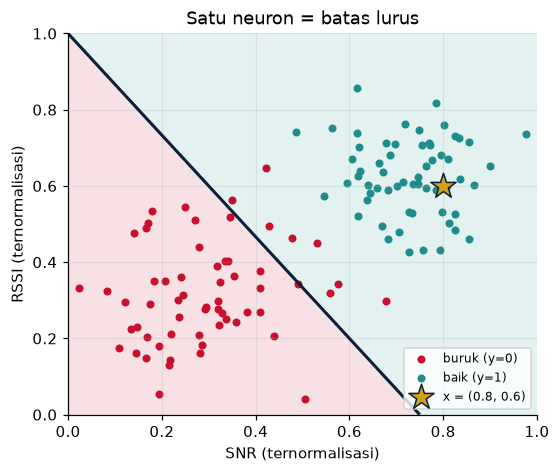

In [4]:
# Data sintetis: 60 link baik dan 60 link buruk (SNR & RSSI ternormalisasi)
n = 60
good = np.column_stack([rng.normal(0.72, 0.12, n), rng.normal(0.65, 0.13, n)])
bad  = np.column_stack([rng.normal(0.30, 0.13, n), rng.normal(0.32, 0.13, n)])

def plot_boundary(ax, predict_fn, title):
    # warnai bidang sesuai prediksi model
    g = np.linspace(0, 1, 200)
    xx, yy = np.meshgrid(g, g)
    grid = np.column_stack([xx.ravel(), yy.ravel()])
    p = predict_fn(grid).reshape(xx.shape)
    ax.contourf(xx, yy, p, levels=[0, 0.5, 1], colors=[RED, TEAL], alpha=0.12)
    ax.contour(xx, yy, p, levels=[0.5], colors=[NAVY], linewidths=2)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_xlabel("SNR (ternormalisasi)"); ax.set_ylabel("RSSI (ternormalisasi)")
    ax.set_title(title)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
plot_boundary(ax, lambda X: sigmoid(X @ w + b), "Satu neuron = batas lurus")
ax.scatter(*bad.T, color=RED, s=18, label="buruk (y=0)")
ax.scatter(*good.T, color=TEAL, s=18, label="baik (y=1)")
ax.scatter(*x, marker="*", s=300, color=GOLD, edgecolor=NAVY, zorder=5, label="x = (0.8, 0.6)")
ax.legend(loc="lower right", fontsize=8)
plt.show()

> **Coba sendiri:** ubah `w` dan `b` di sel sebelumnya (mis. `b = -2.5`), jalankan ulang kedua sel, dan perhatikan garisnya bergeser. *Training* pada dasarnya adalah mencari `w` dan `b` terbaik **secara otomatis**.

---
## 2. Fungsi Aktivasi

### 2.1 Empat fungsi populer & turunannya

Turunan penting karena *backpropagation* mengalikan turunan dari lapisan ke lapisan.

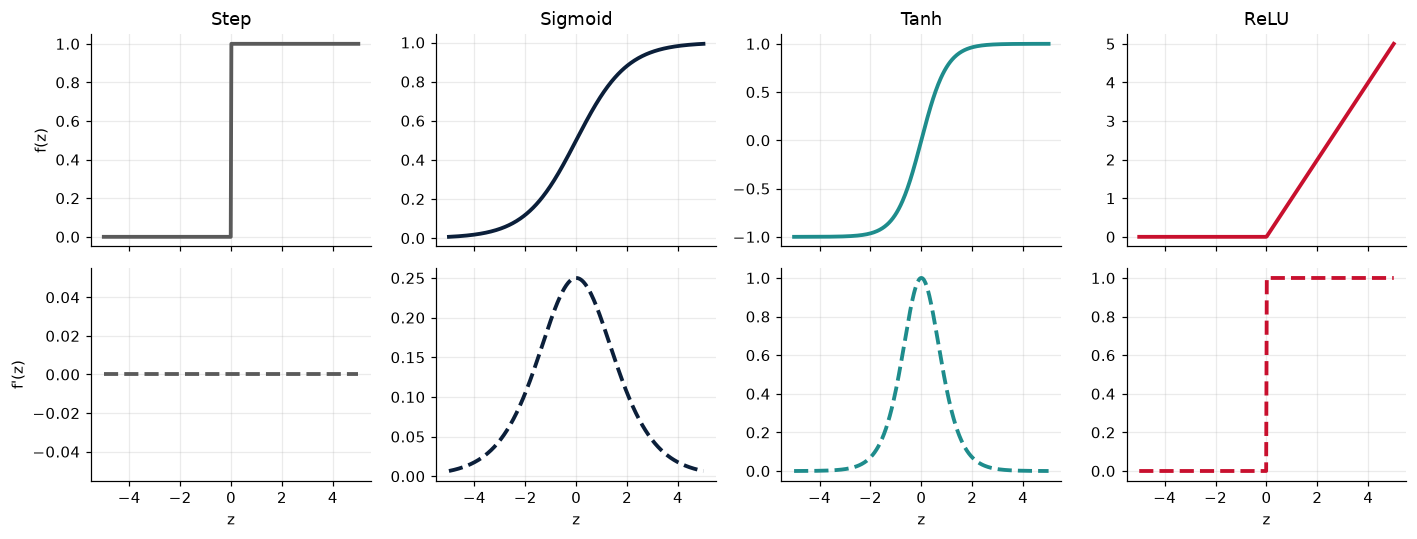

Turunan sigmoid maksimum: 0.25


In [5]:
def step(z):  return np.where(z >= 0, 1.0, 0.0)
def tanh(z):  return np.tanh(z)
def relu(z):  return np.maximum(0, z)

def d_sigmoid(z): s = sigmoid(z); return s * (1 - s)
def d_tanh(z):    return 1 - np.tanh(z) ** 2
def d_relu(z):    return (z > 0).astype(float)
def d_step(z):    return np.zeros_like(z)

zs = np.linspace(-5, 5, 400)
funcs = [("Step", step, d_step, GRAY), ("Sigmoid", sigmoid, d_sigmoid, NAVY),
         ("Tanh", tanh, d_tanh, TEAL), ("ReLU", relu, d_relu, RED)]

fig, axes = plt.subplots(2, 4, figsize=(13, 5), sharex=True)
for j, (name, f, df, c) in enumerate(funcs):
    axes[0, j].plot(zs, f(zs), color=c, lw=2.5); axes[0, j].set_title(name)
    axes[1, j].plot(zs, df(zs), color=c, lw=2.5, ls="--"); axes[1, j].set_xlabel("z")
axes[0, 0].set_ylabel("f(z)"); axes[1, 0].set_ylabel("f'(z)")
plt.tight_layout(); plt.show()

print("Turunan sigmoid maksimum:", d_sigmoid(np.array(0.0)))

### 2.2 *Vanishing gradient*

Turunan sigmoid **paling besar 0.25**. Jika jaringan punya 10 lapisan sigmoid, gradien yang sampai ke lapisan pertama bisa dikalikan $0.25^{10}$:

In [6]:
for layers in [1, 3, 5, 10]:
    print(f"{layers:>2} lapisan sigmoid: faktor gradien <= {0.25 ** layers:.8f}   |  ReLU (z>0): {1.0 ** layers:.0f}")

 1 lapisan sigmoid: faktor gradien <= 0.25000000   |  ReLU (z>0): 1
 3 lapisan sigmoid: faktor gradien <= 0.01562500   |  ReLU (z>0): 1
 5 lapisan sigmoid: faktor gradien <= 0.00097656   |  ReLU (z>0): 1
10 lapisan sigmoid: faktor gradien <= 0.00000095   |  ReLU (z>0): 1


Gradien hampir nol → lapisan awal praktis **berhenti belajar**. ReLU meneruskan gradien apa adanya (×1) untuk $z > 0$, karena itu ReLU menjadi pilihan *default* di *hidden layer*.

### 2.3 Tanpa aktivasi, lapisan bertumpuk tetap linear

Dua lapisan linear $W_2(W_1 x)$ **sama saja** dengan satu lapisan $W' x$ dengan $W' = W_2 W_1$:

In [7]:
W1 = rng.normal(size=(4, 2))   # lapisan 1: 2 -> 4
W2 = rng.normal(size=(1, 4))   # lapisan 2: 4 -> 1
x_demo = np.array([0.8, 0.6])

dua_lapis = W2 @ (W1 @ x_demo)
satu_lapis = (W2 @ W1) @ x_demo
print("W2 (W1 x)  =", dua_lapis)
print("(W2 W1) x  =", satu_lapis, "-> identik! Menumpuk lapisan linear percuma.")

dengan_relu = W2 @ relu(W1 @ x_demo)
print("W2 ReLU(W1 x) =", dengan_relu, "-> berbeda: ReLU membuat model non-linear")

W2 (W1 x)  = [0.2104]
(W2 W1) x  = [0.2104] -> identik! Menumpuk lapisan linear percuma.
W2 ReLU(W1 x) = [-0.2661] -> berbeda: ReLU membuat model non-linear


### 2.4 Softmax untuk multi-kelas

Untuk $K$ kelas (mis. Normal / DoS / Probe), *output layer* memakai softmax agar menghasilkan distribusi peluang yang totalnya 1:

$$\text{softmax}(z_k) = \frac{e^{z_k}}{\sum_j e^{z_j}}$$

In [8]:
def softmax(z):
    e = np.exp(z - np.max(z))   # dikurangi max agar stabil secara numerik
    return e / e.sum()

logits = np.array([2.0, 1.0, 0.1])
probs = softmax(logits)
for kelas, p in zip(["Normal", "DoS", "Probe"], probs):
    print(f"{kelas:<7} {p:.3f}")
print("Total  ", probs.sum())

Normal  0.659
DoS     0.242
Probe   0.099
Total   1.0


---
## 3. *Feed Forward* Jaringan 2-2-1

Kita pakai jaringan yang sama dengan slide: 2 input (SNR, RSSI) → 2 neuron *hidden* (ReLU) → 1 output (sigmoid).

$$h = \text{ReLU}(W^{(1)} x + b^{(1)}) \qquad \hat{y} = \sigma(w^{(2)} \cdot h + b^{(2)})$$

$$W^{(1)} = \begin{pmatrix} 0.5 & -0.3 \\ 0.2 & 0.8 \end{pmatrix},\quad b^{(1)} = \begin{pmatrix} 0.1 \\ -0.2 \end{pmatrix},\quad w^{(2)} = (1.0,\ -0.5),\quad b^{(2)} = 0.2$$

Input $x = (0.8,\ 0.6)$ dengan label $y = 1$ (link baik).

In [9]:
W1 = np.array([[0.5, -0.3],
               [0.2,  0.8]])
b1 = np.array([0.1, -0.2])
w2 = np.array([1.0, -0.5])
b2 = 0.2

x = np.array([0.8, 0.6])
y = 1.0

def forward(x, W1, b1, w2, b2):
    z1 = W1 @ x + b1        # hidden: perkalian matriks + bias
    h = relu(z1)            # aktivasi ReLU
    z2 = w2 @ h + b2        # output
    y_hat = sigmoid(z2)     # aktivasi sigmoid
    return z1, h, z2, y_hat

z1, h, z2, y_hat = forward(x, W1, b1, w2, b2)
print("z1 (hidden)  =", z1)
print("h = ReLU(z1) =", h)
print(f"z2 (output)  = {z2:.2f}")
print(f"y_hat        = {y_hat:.3f}   (target y = {y:.0f})")

z1 (hidden)  = [0.32 0.44]
h = ReLU(z1) = [0.32 0.44]
z2 (output)  = 0.30
y_hat        = 0.574   (target y = 1)


### 3.1 Mengukur kesalahan: *loss function*

- **MSE** (regresi): $L = (y - \hat{y})^2$
- **Binary Cross-Entropy** (klasifikasi biner): $L = -[\,y \ln \hat{y} + (1-y)\ln(1-\hat{y})\,]$

In [10]:
def mse(y, y_hat): return (y - y_hat) ** 2
def bce(y, y_hat): return -(y * np.log(y_hat) + (1 - y) * np.log(1 - y_hat))

print(f"MSE = {mse(y, y_hat):.3f}")
print(f"BCE = {bce(y, y_hat):.3f}")

MSE = 0.181
BCE = 0.554


BCE **menghukum keras** prediksi yang yakin tapi salah. Bandingkan untuk target $y = 1$:

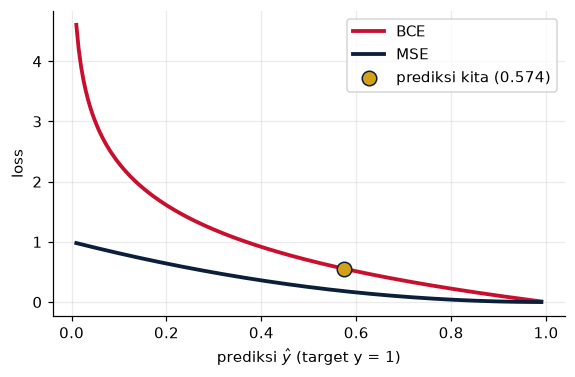

y_hat = 0.990   BCE = 0.010
y_hat = 0.574   BCE = 0.554
y_hat = 0.500   BCE = 0.693
y_hat = 0.010   BCE = 4.605


In [11]:
p = np.linspace(0.01, 0.99, 200)
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(p, bce(1, p), color=RED, lw=2.5, label="BCE")
ax.plot(p, mse(1, p), color=NAVY, lw=2.5, label="MSE")
ax.scatter([y_hat], [bce(y, y_hat)], color=GOLD, edgecolor=NAVY, s=90, zorder=5, label=f"prediksi kita ({y_hat:.3f})")
ax.set_xlabel("prediksi $\\hat{y}$ (target y = 1)"); ax.set_ylabel("loss"); ax.legend()
plt.show()

for p_ in [0.99, y_hat, 0.5, 0.01]:
    print(f"y_hat = {p_:<6.3f}  BCE = {bce(1, p_):.3f}")

---
## 4. *Backpropagation* Manual

Pertanyaannya: **bobot mana yang harus diubah, dan seberapa banyak?** Jawabannya adalah gradien $\partial L / \partial w$ yang dihitung dengan *chain rule*:

$$\frac{\partial L}{\partial w} = \frac{\partial L}{\partial \hat{y}} \cdot \frac{\partial \hat{y}}{\partial z} \cdot \frac{\partial z}{\partial w}$$

Untuk sigmoid + BCE, dua suku pertama menyederhana menjadi $\partial L / \partial z_2 = \hat{y} - y$ ("prediksi dikurangi target").

### 4.1 Output layer

In [12]:
delta_out = y_hat - y          # dL/dz2
grad_w2 = delta_out * h        # dL/dw2 = delta_out * aktivasi asal
grad_b2 = delta_out            # dL/db2

print(f"delta_out = {y_hat:.3f} - {y:.0f} = {delta_out:.3f}")
print("dL/dw2    =", grad_w2)
print(f"dL/db2    = {grad_b2:.3f}")

delta_out = 0.574 - 1 = -0.426
dL/dw2    = [-0.1362 -0.1872]
dL/db2    = -0.426


### 4.2 Hidden layer

Error dibagi mundur sesuai bobot yang menghubungkan, dikali turunan ReLU:

$$\delta_j = \delta_{\text{out}} \cdot w^{(2)}_j \cdot \text{ReLU}'(z_j) \qquad \frac{\partial L}{\partial W^{(1)}_{ji}} = \delta_j \cdot x_i$$

In [13]:
delta_hidden = delta_out * w2 * d_relu(z1)
grad_W1 = np.outer(delta_hidden, x)    # baris j, kolom i: delta_j * x_i
grad_b1 = delta_hidden

print("delta_hidden =", delta_hidden)
print("dL/dW1 =\n", grad_W1)
print("dL/db1 =", grad_b1)

delta_hidden = [-0.4256  0.2128]
dL/dW1 =
 [[-0.3404 -0.2553]
 [ 0.1702  0.1277]]
dL/db1 = [-0.4256  0.2128]


### 4.3 Update bobot dengan *gradient descent* ($\eta = 0.5$)

$$w \leftarrow w - \eta \frac{\partial L}{\partial w}$$

In [14]:
lr = 0.5
W1_new = W1 - lr * grad_W1
b1_new = b1 - lr * grad_b1
w2_new = w2 - lr * grad_w2
b2_new = b2 - lr * grad_b2

print("W1 baru =\n", W1_new)
print("b1 baru =", b1_new)
print("w2 baru =", w2_new)
print(f"b2 baru = {b2_new:.3f}")

_, _, _, y_hat_new = forward(x, W1_new, b1_new, w2_new, b2_new)
print(f"\nSebelum: y_hat = {y_hat:.3f}, BCE = {bce(y, y_hat):.3f}")
print(f"Sesudah: y_hat = {y_hat_new:.3f}, BCE = {bce(y, y_hat_new):.3f}  <- loss turun hampir setengahnya")

W1 baru =
 [[ 0.6702 -0.1723]
 [ 0.1149  0.7362]]
b1 baru = [ 0.3128 -0.3064]
w2 baru = [ 1.0681 -0.4064]
b2 baru = 0.413

Sebelum: y_hat = 0.574, BCE = 0.554
Sesudah: y_hat = 0.753, BCE = 0.283  <- loss turun hampir setengahnya


### 4.4 Cek dengan PyTorch *autograd*

PyTorch menghitung semua gradien di atas **otomatis** dengan `loss.backward()`. Hasilnya harus sama persis dengan perhitungan manual kita:

In [15]:
tW1 = torch.tensor(W1, requires_grad=True)
tb1 = torch.tensor(b1, requires_grad=True)
tw2 = torch.tensor(w2, requires_grad=True)
tb2 = torch.tensor(b2, requires_grad=True, dtype=torch.float64)
tx, ty = torch.tensor(x), torch.tensor(y, dtype=torch.float64)

t_yhat = torch.sigmoid(tw2 @ torch.relu(tW1 @ tx + tb1) + tb2)
loss = nn.functional.binary_cross_entropy(t_yhat, ty)
loss.backward()   # <- backpropagation otomatis

print("autograd dL/dW1 =\n", tW1.grad.numpy())
print("autograd dL/dw2 =", tw2.grad.numpy())
print("Sama dengan manual?",
      np.allclose(tW1.grad.numpy(), grad_W1), np.allclose(tw2.grad.numpy(), grad_w2),
      np.allclose(tb1.grad.numpy(), grad_b1), np.isclose(tb2.grad.item(), grad_b2))

autograd dL/dW1 =
 [[-0.3404 -0.2553]
 [ 0.1702  0.1277]]
autograd dL/dw2 = [-0.1362 -0.1872]
Sama dengan manual? True True True True


### 4.5 Cek numerik (*gradient checking*)

Cara lain memastikan gradien benar: geser satu bobot sedikit ($\varepsilon$) dan lihat perubahan *loss*:
$\frac{\partial L}{\partial w} \approx \frac{L(w+\varepsilon) - L(w-\varepsilon)}{2\varepsilon}$

In [16]:
eps = 1e-6
Wp, Wm = W1.copy(), W1.copy()
Wp[0, 0] += eps; Wm[0, 0] -= eps
L_plus = bce(y, forward(x, Wp, b1, w2, b2)[3])
L_minus = bce(y, forward(x, Wm, b1, w2, b2)[3])
print(f"numerik dL/dW1[0,0] = {(L_plus - L_minus) / (2 * eps):.6f}")
print(f"backprop dL/dW1[0,0] = {grad_W1[0, 0]:.6f}")

numerik dL/dW1[0,0] = -0.340446
backprop dL/dW1[0,0] = -0.340446


---
## 5. *Gradient Descent* & *Learning Rate*

Bayangkan *loss* sebagai bukit: gradien menunjukkan arah menanjak, jadi kita melangkah **berlawanan** arah gradien. Besar langkah ditentukan oleh *learning rate* $\eta$.

Contoh sederhana: $L(w) = \tfrac{1}{2}(w - 2.5)^2$, gradiennya $L'(w) = w - 2.5$, mulai dari $w = -1.5$.

eta = 0.1 (terlalu kecil)    w: -1.50 -> -1.10 -> -0.74 -> -0.42 -> -0.12 -> 0.14 ...
eta = 0.6 (pas)              w: -1.50 -> 0.90 -> 1.86 -> 2.24 -> 2.40 -> 2.46 ...
eta = 1.95 (terlalu besar)   w: -1.50 -> 6.30 -> -1.11 -> 5.93 -> -0.76 -> 5.60 ...


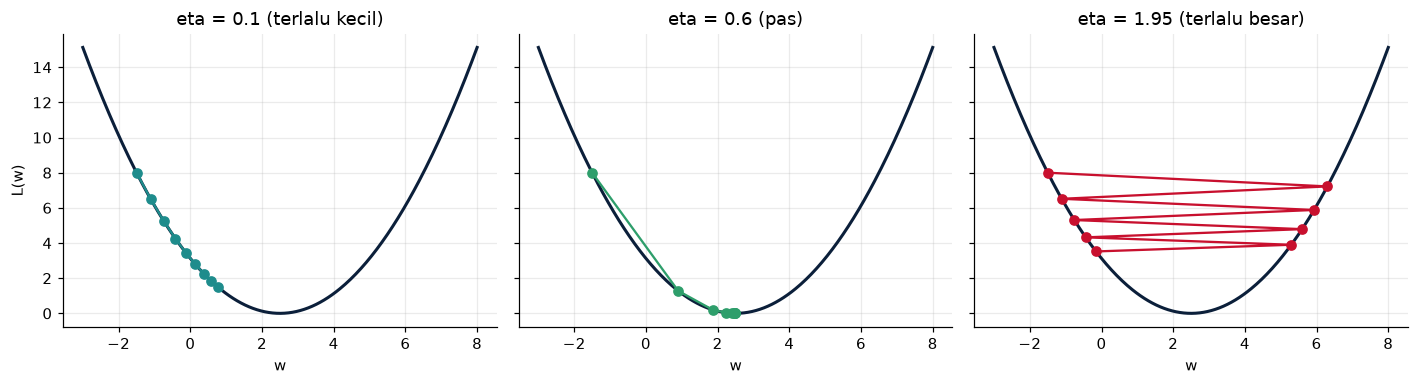

In [17]:
def descend(lr, w0=-1.5, steps=8):
    ws = [w0]
    for _ in range(steps):
        grad = ws[-1] - 2.5
        ws.append(ws[-1] - lr * grad)
    return np.array(ws)

loss_1d = lambda w: 0.5 * (w - 2.5) ** 2
w_axis = np.linspace(-3, 8, 300)
cases = [("eta = 0.1 (terlalu kecil)", 0.1, TEAL), ("eta = 0.6 (pas)", 0.6, GREEN), ("eta = 1.95 (terlalu besar)", 1.95, RED)]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, (title, lr_, c) in zip(axes, cases):
    ws = descend(lr_)
    ax.plot(w_axis, loss_1d(w_axis), color=NAVY, lw=2)
    ax.plot(ws, loss_1d(ws), "o-", color=c, ms=6)
    ax.set_title(title); ax.set_xlabel("w")
    print(f"{title:<28} w: " + " -> ".join(f"{v:.2f}" for v in ws[:6]) + " ...")
axes[0].set_ylabel("L(w)")
plt.tight_layout(); plt.show()

- **Terlalu kecil**: aman tapi lambat, butuh banyak langkah.
- **Pas**: cepat menuju minimum.
- **Terlalu besar**: melompati minimum, bolak-balik, bahkan bisa meledak (*diverge*).

> **Coba sendiri:** ubah `1.95` menjadi `2.1` pada daftar `cases`. Apa yang terjadi pada nilai `w`?

---
## 6. Melatih MLP Kecil dengan PyTorch

Sekarang kita biarkan PyTorch mencari bobot sendiri. Kita buat **data sintetis yang tidak bisa dipisah garis lurus**: link dianggap baik hanya jika SNR **dan** RSSI berada di "zona ideal" (pola seperti XOR/cincin), supaya terlihat mengapa *hidden layer* dibutuhkan.

### 6.1 Data sintetis non-linear

train: torch.Size([480, 2])  val: torch.Size([120, 2])  proporsi 'baik': 0.26


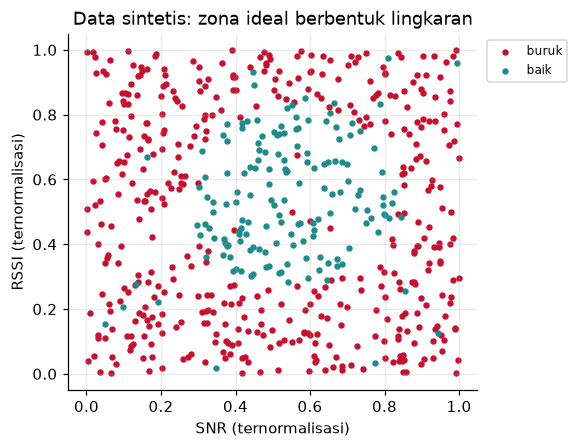

In [18]:
N = 600
X_np = rng.uniform(0, 1, size=(N, 2))
# "baik" jika titik berada di dalam lingkaran zona ideal (pusat 0.55, 0.55)
dist = np.sqrt(((X_np - 0.55) ** 2).sum(axis=1))
y_np = (dist < 0.28).astype(np.float32)
flip = rng.random(N) < 0.05          # 5% label noise, seperti data nyata
y_np[flip] = 1 - y_np[flip]

# bagi data: 80% train, 20% validasi
idx = rng.permutation(N)
tr, va = idx[:480], idx[480:]
X_train, y_train = torch.tensor(X_np[tr], dtype=torch.float32), torch.tensor(y_np[tr]).unsqueeze(1)
X_val, y_val = torch.tensor(X_np[va], dtype=torch.float32), torch.tensor(y_np[va]).unsqueeze(1)
print("train:", X_train.shape, " val:", X_val.shape, " proporsi 'baik':", y_np.mean().round(2))

fig, ax = plt.subplots(figsize=(4.8, 4.2))
ax.scatter(*X_np[y_np == 0].T, color=RED, s=10, label="buruk")
ax.scatter(*X_np[y_np == 1].T, color=TEAL, s=10, label="baik")
ax.set_xlabel("SNR (ternormalisasi)"); ax.set_ylabel("RSSI (ternormalisasi)")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
ax.set_title("Data sintetis: zona ideal berbentuk lingkaran")
plt.show()

### 6.2 Mendefinisikan model

Dua model untuk dibandingkan:
- **Satu neuron** (tanpa *hidden layer*) → hanya bisa batas lurus
- **MLP 2-16-16-1** dengan ReLU

`nn.Linear(n_in, n_out)` = $Wx + b$. Output tidak diberi sigmoid karena `BCEWithLogitsLoss` sudah menggabungkan sigmoid + BCE (lebih stabil).

In [19]:
def make_single_neuron():
    return nn.Sequential(nn.Linear(2, 1))

def make_mlp():
    return nn.Sequential(
        nn.Linear(2, 16), nn.ReLU(),
        nn.Linear(16, 16), nn.ReLU(),
        nn.Linear(16, 1),
    )

def count_params(model):
    return sum(p.numel() for p in model.parameters())

print(make_mlp())
print("Parameter satu neuron:", count_params(make_single_neuron()))
print("Parameter MLP 2-16-16-1:", count_params(make_mlp()), "= (2*16+16) + (16*16+16) + (16*1+1)")

Sequential(
  (0): Linear(in_features=2, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=16, bias=True)
  (3): ReLU()
  (4): Linear(in_features=16, out_features=1, bias=True)
)
Parameter satu neuron: 3
Parameter MLP 2-16-16-1: 337 = (2*16+16) + (16*16+16) + (16*1+1)


### 6.3 *Training loop*

Lima langkah yang diulang setiap *batch* — persis seperti di slide:

1. **forward** — `model(xb)`
2. **loss** — `loss_fn(logits, yb)`
3. **reset** — `optimizer.zero_grad()`
4. **backward** — `loss.backward()`
5. **update** — `optimizer.step()`

In [20]:
def train(model, epochs=150, lr=0.01, batch_size=32):
    loss_fn = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loader = torch.utils.data.DataLoader(
        torch.utils.data.TensorDataset(X_train, y_train), batch_size=batch_size, shuffle=True
    )
    history = {"train": [], "val": []}
    for epoch in range(epochs):
        model.train()
        for xb, yb in loader:                 # satu iterasi = satu batch
            logits = model(xb)                # 1. forward
            loss = loss_fn(logits, yb)        # 2. loss
            optimizer.zero_grad()             # 3. reset gradien
            loss.backward()                   # 4. backward (backprop)
            optimizer.step()                  # 5. update bobot
        model.eval()
        with torch.no_grad():
            history["train"].append(loss_fn(model(X_train), y_train).item())
            history["val"].append(loss_fn(model(X_val), y_val).item())
    return history

def accuracy(model, X, y):
    with torch.no_grad():
        pred = (torch.sigmoid(model(X)) > 0.5).float()
    return (pred == y).float().mean().item()

torch.manual_seed(SEED)
single = make_single_neuron()
hist_single = train(single)
torch.manual_seed(SEED)
mlp = make_mlp()
hist_mlp = train(mlp)

print(f"Iterasi per epoch: {int(np.ceil(len(X_train) / 32))}  (480 data / batch 32)")
print(f"Tebak 'buruk' semua (baseline) -> akurasi val = {1 - y_val.mean().item():.2%}")
print(f"Satu neuron  -> akurasi val = {accuracy(single, X_val, y_val):.2%}")
print(f"MLP 2-16-16-1 -> akurasi val = {accuracy(mlp, X_val, y_val):.2%}")

Iterasi per epoch: 15  (480 data / batch 32)
Tebak 'buruk' semua (baseline) -> akurasi val = 75.83%
Satu neuron  -> akurasi val = 75.83%
MLP 2-16-16-1 -> akurasi val = 90.00%


### 6.4 Kurva *loss* & batas keputusan

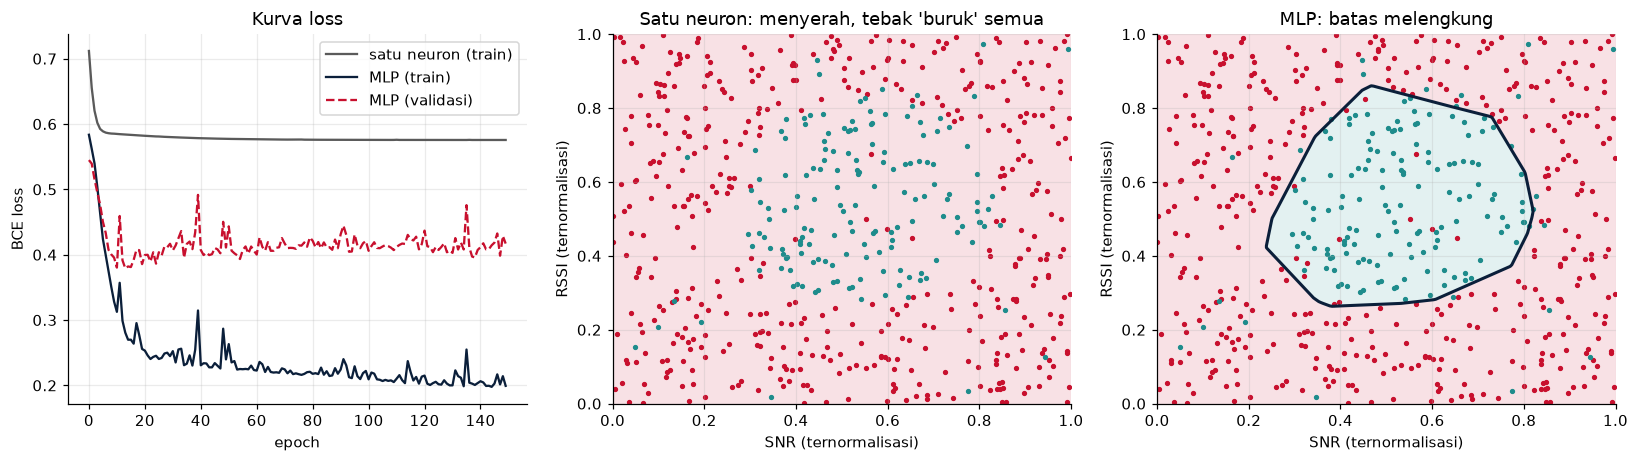

In [21]:
def torch_predict(model):
    def f(X):
        with torch.no_grad():
            return torch.sigmoid(model(torch.tensor(X, dtype=torch.float32))).numpy().ravel()
    return f

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
axes[0].plot(hist_single["train"], color=GRAY, label="satu neuron (train)")
axes[0].plot(hist_mlp["train"], color=NAVY, label="MLP (train)")
axes[0].plot(hist_mlp["val"], color=RED, ls="--", label="MLP (validasi)")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("BCE loss"); axes[0].legend(); axes[0].set_title("Kurva loss")

for ax, model, title in [(axes[1], single, "Satu neuron: menyerah, tebak 'buruk' semua"), (axes[2], mlp, "MLP: batas melengkung")]:
    plot_boundary(ax, torch_predict(model), title)
    ax.scatter(*X_np[y_np == 0].T, color=RED, s=6)
    ax.scatter(*X_np[y_np == 1].T, color=TEAL, s=6)
plt.tight_layout(); plt.show()

Satu neuron hanya bisa menarik **garis lurus**. Tidak ada satu garis pun yang bisa memisahkan zona lingkaran, sehingga solusi terbaiknya adalah menebak "buruk" untuk semua titik — akurasinya hampir sama dengan *baseline*. MLP dengan *hidden layer* + ReLU "menekuk" batas keputusan sehingga bisa melingkupinya.

> **Coba sendiri:** ganti `nn.ReLU()` di `make_mlp` menjadi `nn.Sigmoid()`, atau ubah `lr=0.01` menjadi `lr=1.0` di `train(...)`. Bagaimana kurva *loss*-nya?

### 6.5 Waspada *overfitting*

Model yang terlalu besar untuk data yang sedikit akan **menghafal** data latih, termasuk noise-nya. Kita latih MLP besar hanya dengan 40 sampel:

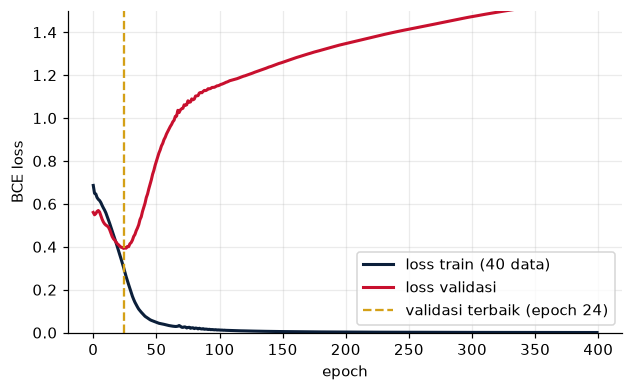

Akurasi train = 100%, akurasi validasi = 84%


In [22]:
X_small, y_small = X_train[:40], y_train[:40]

torch.manual_seed(SEED)
big = nn.Sequential(nn.Linear(2, 128), nn.ReLU(), nn.Linear(128, 128), nn.ReLU(), nn.Linear(128, 1))
loss_fn = nn.BCEWithLogitsLoss()
opt = torch.optim.Adam(big.parameters(), lr=0.01)
tr_hist, va_hist = [], []
for epoch in range(400):
    big.train()
    loss = loss_fn(big(X_small), y_small)   # full batch (40 data)
    opt.zero_grad(); loss.backward(); opt.step()
    big.eval()
    with torch.no_grad():
        tr_hist.append(loss.item()); va_hist.append(loss_fn(big(X_val), y_val).item())

best = int(np.argmin(va_hist))
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(tr_hist, color=NAVY, lw=2, label="loss train (40 data)")
ax.plot(va_hist, color=RED, lw=2, label="loss validasi")
ax.axvline(best, color=GOLD, ls="--", label=f"validasi terbaik (epoch {best})")
ax.set_xlabel("epoch"); ax.set_ylabel("BCE loss"); ax.set_ylim(0, 1.5); ax.legend()
plt.show()
print(f"Akurasi train = {accuracy(big, X_small, y_small):.0%}, akurasi validasi = {accuracy(big, X_val, y_val):.0%}")

*Loss* train terus turun mendekati nol, tetapi *loss* validasi berhenti membaik lalu naik — tanda **overfitting**. Solusinya: *early stopping* (ambil model di titik emas), *dropout*, *weight decay*, atau menambah data.

---
## 7. Jembatan ke *Pipeline* Deteksi Intrusi (`.py`)

Semua konsep di atas akan kita pakai ulang pada data NSL-KDD:

| Konsep di notebook ini | Di *pipeline* NSL-KDD |
|---|---|
| 2 fitur (SNR, RSSI) dinormalisasi | 41 fitur koneksi → *one-hot* + *standardization* → **122 fitur** |
| MLP 2-16-16-1 | MLP **122-64-32-1** |
| `BCEWithLogitsLoss` + Adam | sama |
| *Training loop* 5 langkah | sama, ditulis di file `.py` |
| Akurasi validasi | akurasi, *precision*, *recall*, F1, *confusion matrix* |

Arsitektur yang akan kita tulis:

In [23]:
ids_model = nn.Sequential(
    nn.Linear(122, 64), nn.ReLU(),   # input -> hidden 1
    nn.Linear(64, 32), nn.ReLU(),    # hidden 1 -> hidden 2
    nn.Linear(32, 1),                # hidden 2 -> output (logit)
)
print(ids_model)
print("Total parameter:", count_params(ids_model))   # 9.985, sama dengan slide

dummy = torch.randn(5, 122)          # 5 koneksi palsu, hanya untuk cek bentuk tensor
print("Output shape:", ids_model(dummy).shape)

Sequential(
  (0): Linear(in_features=122, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=32, bias=True)
  (3): ReLU()
  (4): Linear(in_features=32, out_features=1, bias=True)
)
Total parameter: 9985
Output shape: torch.Size([5, 1])


---
## Latihan

**Latihan 1 (dari slide).** Gunakan jaringan 2-2-1 di Bagian 3 (bobot awal) untuk link dengan $x = (0.2,\ 0.3)$ dan label $y = 0$ (link buruk). Hitung $h$, $\hat{y}$, dan $L_{\text{BCE}}$ **di kertas dulu**, lalu cek dengan sel di bawah.

**Latihan 2.** Berapa parameter MLP **122-128-64-5** untuk klasifikasi 5 kelas NSL-KDD? Aktivasi dan *loss* apa yang dipakai di output? Cek jawabanmu dengan `count_params`.

In [24]:
# Latihan 1 — jalankan setelah menghitung manual
x_bad, y_bad = np.array([0.2, 0.3]), 0.0
z1_b, h_b, z2_b, yhat_b = forward(x_bad, W1, b1, w2, b2)
print("h =", h_b, f"| z2 = {z2_b:.2f} | y_hat = {yhat_b:.3f} | BCE = {bce(y_bad, yhat_b):.3f}")
print("Prediksi:", "BAIK" if yhat_b > 0.5 else "BURUK", "(label sebenarnya: BURUK)")

h = [0.11 0.08] | z2 = 0.27 | y_hat = 0.567 | BCE = 0.837
Prediksi: BAIK (label sebenarnya: BURUK)


In [25]:
# Latihan 2 — lengkapi arsitekturnya, lalu jalankan
multi = nn.Sequential(
    nn.Linear(122, 128), nn.ReLU(),
    nn.Linear(128, 64), nn.ReLU(),
    nn.Linear(64, 5),                # 5 logit -> softmax ada di dalam nn.CrossEntropyLoss
)
print("Total parameter:", count_params(multi))

Total parameter: 24325


---
## Ringkasan

1. **Neuron** = penjumlahan berbobot + fungsi aktivasi: $\hat{y} = f(\sum w_i x_i + b)$.
2. **Aktivasi non-linear** (ReLU) membuat lapisan bertumpuk bisa membentuk batas keputusan melengkung.
3. ***Feed forward*** menghitung prediksi lapis demi lapis; ***loss*** mengukur seberapa salah.
4. ***Backpropagation*** memakai *chain rule* untuk menghitung gradien; ***gradient descent*** memperbarui bobot. PyTorch melakukannya otomatis lewat `loss.backward()` dan `optimizer.step()`.

**Berikutnya:** menulis *pipeline* `.py` lengkap untuk melatih ANN deteksi intrusi pada NSL-KDD.